# SCIKIT-LEARN MASTERY — NOTEBOOK 12
## Chapters 67–72: Model Versioning → Production Inference → API/Deployment Awareness → MLOps Connection → Model Monitoring → END-TO-END PROJECT #1: Customer Churn Prediction System

Continuing directly from Notebook 11. This notebook closes with your first complete, portfolio-quality end-to-end project.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–66 *(Notebooks 1–11)*
- [x] Model Versioning
- [x] Production Inference
- [x] API / Deployment Awareness
- [x] MLOps Connection
- [x] Model Monitoring
- [x] **End-to-End Project #1: Customer Churn Prediction System**


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
np.random.seed(42)


---
# CHAPTER 67 — MODEL VERSIONING

## 1. Concept
A production model is never truly "done" — it will be retrained, retuned, and redeployed repeatedly over its lifetime. Without disciplined versioning, it becomes impossible to answer basic questions like "which exact data and code produced the model currently running in production?" — a real operational and audit risk.

## 2. What Needs to Be Versioned Together
| Component | Why it matters |
|---|---|
| **Model version** | The specific trained artifact (weights/parameters) — even identical code + data can produce a slightly different model run to run without a fixed `random_state` |
| **Dataset version** | Training data itself changes over time (new records, corrections, schema changes) — a model's behavior is meaningless without knowing exactly what data produced it |
| **Feature version** | Feature engineering logic evolves — the same column name might mean something subtly different after a pipeline update |
| **Code version** | The exact training script/notebook commit that produced the model |
| **Dependency version** | Library versions (Scikit-learn, NumPy) — as Chapter 66 established, these can genuinely affect model behavior |
| **Experiment configuration** | Hyperparameters, random seeds, CV strategy used |

## 3. A Practical, Minimal Versioning Pattern


In [43]:
import joblib
import json
import hashlib
from datetime import datetime, timezone

def save_versioned_model(pipeline, X_train, metadata_extra=None, output_dir="/home/claude/models"):
    """Save a model alongside a metadata manifest capturing everything needed to reproduce it."""
    import os, sklearn
    os.makedirs(output_dir, exist_ok=True)

    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    # A simple content hash of the training data, so we can later VERIFY which exact data
    # (not just "a dataset that looked similar") produced this specific model
    data_hash = hashlib.sha256(pd.util.hash_pandas_object(X_train).values.tobytes()).hexdigest()[:16]

    model_filename = f"model_{timestamp}.joblib"
    model_path = os.path.join(output_dir, model_filename)
    joblib.dump(pipeline, model_path)

    metadata = {
        "timestamp_utc": timestamp,
        "model_filename": model_filename,
        "sklearn_version": sklearn.__version__,
        "numpy_version": np.__version__,
        "training_data_shape": list(X_train.shape),
        "training_data_hash": data_hash,
        "pipeline_steps": list(pipeline.named_steps.keys()) if hasattr(pipeline, "named_steps") else None,
    }
    if metadata_extra:
        metadata.update(metadata_extra)

    metadata_path = os.path.join(output_dir, f"model_{timestamp}_metadata.json")
    with open(metadata_path, "w") as f:
        json.dump(metadata, f, indent=2)

    return model_path, metadata_path, metadata


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_ver = pd.DataFrame(np.random.randn(200, 4), columns=[f"f{i}" for i in range(4)])
y_ver = np.random.randint(0, 2, 200)
demo_pipeline = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression())]).fit(X_ver, y_ver)

model_path, metadata_path, metadata = save_versioned_model(
    demo_pipeline, X_ver,
    metadata_extra={"cv_roc_auc": 0.87, "trained_by": "notebook_12_demo", "git_commit": "abc1234"},
)
print("Saved model:", model_path)
print("Saved metadata:", metadata_path)
print(json.dumps(metadata, indent=2))


Saved model: /home/claude/models/model_20261004T143029Z.joblib
Saved metadata: /home/claude/models/model_20261004T143029Z_metadata.json
{
  "timestamp_utc": "20261004T143029Z",
  "model_filename": "model_20261004T143029Z.joblib",
  "sklearn_version": "1.6.1",
  "numpy_version": "2.1.3",
  "training_data_shape": [
    200,
    4
  ],
  "training_data_hash": "1d2156fa8a5a7907",
  "pipeline_steps": [
    "scaler",
    "model"
  ],
  "cv_roc_auc": 0.87,
  "trained_by": "notebook_12_demo",
  "git_commit": "abc1234"
}


### Line-by-Line Explanation
- `data_hash` — a cryptographic hash of the actual training data's content, not just its shape or a filename — this lets you later definitively verify "was this the exact same data" (any change, even one cell value, produces a completely different hash), a much stronger guarantee than a filename or a manually-written description could provide.
- The metadata JSON is saved **alongside** the model artifact, not embedded inside it — keeping it in a plain, human/tool-readable format (rather than needing to load the model itself just to inspect its provenance) and making it easy to search/query across many saved models without loading each one.
- `git_commit` (as a placeholder field here) — in a real project, this would be populated programmatically (e.g., via `git rev-parse HEAD`) to link the model artifact directly to the exact code version that produced it.

### Common Mistakes
- Saving a new model over the same filename repeatedly ("latest_model.joblib") — destroys the ability to compare against or roll back to a previous version, a serious operational risk if a new model turns out to perform worse in production than expected.
- Recording hyperparameters but not the training data's identity — two models trained with identical code and hyperparameters on genuinely different data snapshots are different models, and without a data version/hash, this distinction is invisible.
- Treating versioning as unnecessary for "just a small project" — the discipline costs very little to establish early and becomes extremely costly to retrofit once a project has many historical model versions already in ambiguous, unlabeled states.

### Interview Insight
**Q: Six months after deployment, a model's predictions look subtly different from what you remember validating. What would proper versioning have let you check?**
A: With full versioning, you could load the exact metadata for the currently-deployed model and check: (1) is this genuinely the model you validated, or did a redeployment silently swap in a newer, different version? (2) does the training data hash match what you expect, or was the model retrained on updated/corrected data since your last review? (3) do the recorded library versions match the current serving environment, ruling out (or confirming) a dependency-version behavioral shift (Chapter 66)? Without this metadata, diagnosing "why does this look different" becomes largely guesswork, since none of these specific hypotheses can be directly checked or ruled out.

### Quiz (Chapter 67)
1. List the 6 components that should be versioned together with a model.
2. Why is a content hash of the training data more reliable than a filename or description for verifying data identity?
3. What operational risk does overwriting the same model filename repeatedly create?


---
# CHAPTER 68 — PRODUCTION INFERENCE

## 1. Concept — The Full Inference Flow
```
Raw User Input
     ↓
Input Validation          -- schema check, required fields present, types correct
     ↓
Saved Pipeline (loaded)   -- exactly the training-time preprocessing + model, joblib-persisted
     ↓
Transformation            -- .transform() through every preprocessing step, unchanged from training
     ↓
Model Prediction          -- .predict() / .predict_proba()
     ↓
Post-processing           -- threshold applied (Chapter 30), formatting for the consuming system
     ↓
Business Decision / Response
```

The single most important production-inference guarantee, stated precisely: **the exact same code path (the saved Pipeline) must handle preprocessing at both training and inference time** — this is precisely what Chapter 66's "save the whole Pipeline, not just the model" practice exists to guarantee.

## 2. A Realistic Inference Function


In [44]:
import joblib
import pandas as pd

class InferenceError(Exception):
    """Raised when input validation fails -- a deliberate, informative failure rather than a cryptic sklearn error."""
    pass


def validate_input(raw_input: dict, required_fields: dict):
    """required_fields: dict of {field_name: expected_type}"""
    missing = [f for f in required_fields if f not in raw_input]
    if missing:
        raise InferenceError(f"Missing required fields: {missing}")

    wrong_type = []
    for field, expected_type in required_fields.items():
        if not isinstance(raw_input[field], expected_type):
            wrong_type.append(f"{field} (expected {expected_type.__name__ if not isinstance(expected_type, tuple) else ' or '.join([t.__name__ for t in expected_type])}, got {type(raw_input[field]).__name__})")
    if wrong_type:
        raise InferenceError(f"Type mismatches: {wrong_type}")


def run_inference(raw_input: dict, pipeline_path: str, required_fields: dict, decision_threshold: float = 0.5):
    """The full production inference flow, from raw dict input to a business decision."""
    validate_input(raw_input, required_fields)

    pipeline = joblib.load(pipeline_path)   # in a REAL system, this would be loaded ONCE at service startup, not per-request
    X_new = pd.DataFrame([raw_input])

    # The demo model from Chapter 67 is a Pipeline; we obtain the predictions using the correct methods
    if hasattr(pipeline, "predict_proba"):
        proba = pipeline.predict_proba(X_new)[0, 1]
    else:
        proba = 0.5  # Fallback if model doesn't support predict_proba

    decision = "FLAG_FOR_REVIEW" if proba >= decision_threshold else "APPROVE"

    return {
        "probability": round(float(proba), 4),
        "decision": decision,
        "threshold_used": decision_threshold,
    }


# Reuse the model saved in Chapter 66/67's demo dynamically
try:
    # Use the model path generated dynamically in Chapter 67
    active_model_path = model_path
except NameError:
    active_model_path = "/home/claude/models/churn_pipeline_v1.joblib"

required_schema = {"age": (int, float), "income": (int, float), "city": str}

# Prepare input compatible with our trained model's feature names (f0, f1, f2, f3)
good_request = {"f0": 0.5, "f1": -0.2, "f2": 1.1, "f3": -0.5}
required_schema_demo = {"f0": (int, float), "f1": (int, float), "f2": (int, float), "f3": (int, float)}

try:
    result = run_inference(good_request, active_model_path, required_schema_demo, decision_threshold=0.5)
    print("Valid request result:", result)
except InferenceError as e:
    print("Validation error:", e)
except FileNotFoundError:
    print(f"Could not find model file at: {active_model_path}")

# An INVALID request -- missing a required field
bad_request = {"f0": 0.5, "f1": -0.2}   # missing features
try:
    run_inference(bad_request, active_model_path, required_schema_demo, decision_threshold=0.5)
except InferenceError as e:
    print("\nInvalid request correctly caught:", e)
except FileNotFoundError:
    print(f"Could not find model file at: {active_model_path}")

Valid request result: {'probability': 0.3703, 'decision': 'APPROVE', 'threshold_used': 0.5}

Invalid request correctly caught: Missing required fields: ['f2', 'f3']


### Line-by-Line Explanation
- `validate_input()` runs **before** the model ever sees the data — deliberately failing fast with a clear, actionable `InferenceError` message rather than letting a malformed request produce a cryptic downstream Scikit-learn error (or worse, a silently wrong prediction) deep inside the pipeline.
- Loading the pipeline **inside** `run_inference()` (as written) is deliberately flagged as **not** how a real system should work — in production, the model is loaded **once** when the service starts, and reused across every subsequent request; reloading from disk on every single request would be a serious, unnecessary latency and I/O cost, worth calling out explicitly even in an illustrative function.
- `pd.DataFrame([raw_input])` — wraps a single dict into a one-row DataFrame, exactly matching the shape/column-name structure the Pipeline's `ColumnTransformer` expects (Chapter 3's shape rules, now applied to a genuine single-prediction production request).

### Common Mistakes
- Skipping input validation and letting malformed requests hit the model directly — produces confusing internal errors (or, worse, silently wrong predictions if a value happens to coerce into a valid-looking type) instead of a clear, actionable rejection at the boundary.
- Reloading the model from disk on every single inference request — a serious avoidable latency cost in any real service; load once at startup.
- Hardcoding a decision threshold without making it a configurable parameter — as Chapter 30 established, the "right" threshold can change (as costs/business context shift) independent of the model itself, and hardcoding it forces a full redeployment for what should be a simple configuration change.

### Interview Insight
**Q: Why should input validation happen as an explicit, separate step before the model even sees the request, rather than just letting Scikit-learn's own errors surface?**
A: Scikit-learn's internal errors (shape mismatches, encoding errors, `NotFittedError`) are designed for developers debugging code, not for a production system's real-time request handling — they can be cryptic, may not clearly indicate *which* specific field was wrong, and in some cases a malformed-but-technically-valid-shaped input might not error at all, instead silently producing a meaningless prediction (e.g., a string accidentally coerced into an unexpected value). Explicit input validation at the service boundary produces clear, actionable error messages tied directly to the actual problem (a missing field, a wrong type), fails fast before any wasted computation, and is the correct layer for handling malformed real-world input in any production system, regardless of the specific ML library underneath.

### Quiz (Chapter 68)
1. Draw out the full production inference flow from raw input to business decision, in order.
2. Why is loading the model once at service startup preferred over loading it per-request?
3. Why should the decision threshold be a configurable parameter rather than hardcoded?


---
# CHAPTER 69 — API / DEPLOYMENT AWARENESS

## 1. Concept
A trained Scikit-learn Pipeline needs to be exposed for consumption — commonly via a REST API (real-time single/batch predictions), a scheduled batch job (large periodic scoring runs), or a cloud ML platform's managed endpoint. This chapter builds *awareness* of these patterns at the level an ML engineer needs (what shape the deployment takes, what their responsibility is), without turning into a full backend engineering course.

## 2. Real-Time API (Conceptual Sketch — FastAPI)
```python
from fastapi import FastAPI
from pydantic import BaseModel
import joblib

app = FastAPI()
pipeline = joblib.load("churn_pipeline_v1.joblib")   # loaded ONCE at startup (Chapter 68's lesson)

class ChurnRequest(BaseModel):   # pydantic automatically validates types/required fields --
    age: float                    # a more robust, declarative version of Chapter 68's validate_input()
    income: float
    city: str

@app.post("/predict")
def predict(request: ChurnRequest):
    X_new = pd.DataFrame([request.dict()])
    proba = pipeline.predict_proba(X_new)[0, 1]
    return {"churn_probability": round(float(proba), 4)}
```

## 3. Batch Inference (Runnable — the Pattern You'll Actually Use Most Often)


In [45]:
import joblib
import pandas as pd
import numpy as np
import os

def run_batch_inference(input_df: pd.DataFrame, pipeline_path: str, decision_threshold: float = 0.5) -> pd.DataFrame:
    """Score an entire DataFrame at once -- the standard pattern for a scheduled batch job
    (e.g., 'score all active customers nightly and write results to a table')."""
    pipeline = joblib.load(pipeline_path)

    probas = pipeline.predict_proba(input_df)[:, 1]
    decisions = np.where(probas >= decision_threshold, "FLAG_FOR_REVIEW", "APPROVE")

    results = input_df.copy()
    results["churn_probability"] = probas.round(4)
    results["decision"] = decisions
    results["scored_at"] = pd.Timestamp.now(tz="UTC")
    return results


# Dynamically check for a valid model path generated in our notebook sessions
try:
    # Prefer the final trained model from Chapter 72 if it was executed
    if 'final_model_path' in globals() and os.path.exists(final_model_path):
        active_path = final_model_path
        # Prepare input matching the customer churn schema
        batch_input = pd.DataFrame({
            "tenure_months": np.random.exponential(24, 20).round(1).clip(0, 72),
            "monthly_charges": np.random.exponential(65, 20).round(2),
            "total_charges": np.random.exponential(1500, 20).round(2),
            "contract_type": np.random.choice(["Month-to-month", "One year", "Two year"], 20),
            "internet_service": np.random.choice(["DSL", "Fiber optic", "No"], 20),
            "payment_method": np.random.choice(["Electronic check", "Mailed check", "Bank transfer", "Credit card"], 20),
            "num_support_tickets": np.random.poisson(1.8, 20),
            "has_tech_support": np.random.choice(["Yes", "No"], 20),
            "senior_citizen": np.random.choice([0, 1], 20),
        })
    else:
        # Fallback to the Chapter 67 demo model
        active_path = model_path
        batch_input = pd.DataFrame({
            "f0": np.random.randn(20),
            "f1": np.random.randn(20),
            "f2": np.random.randn(20),
            "f3": np.random.randn(20),
        })
except NameError:
    active_path = "/home/claude/models/churn_pipeline_v1.joblib"
    batch_input = pd.DataFrame()

if not batch_input.empty:
    try:
        batch_results = run_batch_inference(batch_input, active_path)
        print(batch_results.head())
        print(f"\n{(batch_results['decision'] == 'FLAG_FOR_REVIEW').sum()} of {len(batch_results)} flagged for review")
    except FileNotFoundError:
        print(f"Could not find model file at: {active_path}")
else:
    print("Could not run batch inference: No valid trained model found in memory.")

   tenure_months  monthly_charges  total_charges   contract_type  \
0           11.2           123.57           9.61        Two year   
1            7.2           131.28         507.49  Month-to-month   
2           30.8            80.10        1439.29        One year   
3           16.4           117.92        5959.75  Month-to-month   
4            2.0            77.71        1498.75        One year   

  internet_service    payment_method  num_support_tickets has_tech_support  \
0               No     Bank transfer                    3              Yes   
1              DSL  Electronic check                    2               No   
2      Fiber optic  Electronic check                    2              Yes   
3               No     Bank transfer                    0               No   
4               No       Credit card                    3               No   

   senior_citizen  churn_probability         decision  \
0               0             0.2408          APPROVE   
1       

### Line-by-Line Explanation
- Batch inference scores an **entire DataFrame in one vectorized `.predict_proba()` call**, rather than looping row by row — dramatically faster for large volumes, since it leverages NumPy's vectorized operations throughout the pipeline instead of paying Python-loop overhead per row.
- `scored_at` — a timestamp recorded with every batch of predictions is a small but genuinely important production habit, directly supporting the model monitoring work in Chapter 71 (knowing *when* a given prediction was made is essential for any time-based drift or performance analysis later).

## 4. Real-Time vs. Batch — Choosing Between Them
| | Real-time API | Batch |
|---|---|---|
| Latency requirement | Immediate (milliseconds-seconds) | Can tolerate delay (minutes-hours) |
| Typical use case | User-facing feature (e.g., live fraud check during checkout) | Nightly scoring of an entire customer base |
| Infrastructure | A running service (FastAPI/Flask behind a load balancer, or a managed cloud endpoint) | A scheduled job (cron, Airflow, cloud batch service) |
| Cost profile | Pay for an always-on (or auto-scaling) service | Pay only for the compute during the actual scoring run |

## 5. The ML Engineer's Actual Responsibility Boundary
Building the full production API/service infrastructure (authentication, load balancing, deployment orchestration) is typically **backend/platform engineering** territory. The ML engineer's core responsibility is: (1) the trained, versioned, correctly-persisted Pipeline (Chapters 66–67), (2) the input validation and inference logic (Chapter 68), and (3) clear documentation of the expected input schema and output format — handing off a clean, well-defined contract that backend engineers can wrap in whatever service infrastructure the broader system requires.

### Common Mistakes
- Building batch inference as a row-by-row Python loop instead of one vectorized call over the whole DataFrame — a significant, easily-avoidable performance cost.
- Not recording a timestamp with batch predictions — makes later monitoring/drift analysis (Chapter 71) much harder, since you can't reconstruct exactly when a given historical prediction was made.
- ML engineers over-extending into full backend/infrastructure engineering without the relevant expertise, when the more effective contribution is a clean, well-documented model artifact and inference contract that specialists can build reliable infrastructure around.

### Interview Insight
**Q: Your team needs to score 5 million customer records nightly to flag potential churners. Would you build this as a real-time API or a batch job, and why?**
A: A batch job — nightly scoring of an entire customer base has no real-time latency requirement (the results are consumed the next business day, not instantaneously), and batch processing 5 million records in one vectorized pass is far more efficient (both in compute cost and simplicity) than standing up and maintaining an always-on API service that would mostly sit idle outside the nightly run. A real-time API would make sense instead for a genuinely latency-sensitive use case, like a live fraud check needed *during* a checkout flow, where the prediction must inform an immediate user-facing decision.

### Quiz (Chapter 69)
1. What's the key deciding factor between choosing a real-time API vs. a batch job for a given ML use case?
2. Why should batch inference be one vectorized call over the whole DataFrame rather than a row-by-row loop?
3. What is the ML engineer's typical responsibility boundary versus backend/platform engineering's, in a production ML deployment?


---
# CHAPTER 70 — MLOPS CONNECTION

## 1. Concept — Where Scikit-learn Ends and MLOps Tooling Begins

```
Data
  ↓
Training  ................................ Scikit-learn (this entire course)
  ↓
Experiment Tracking ....................... MLflow / Weights & Biases (NOT Scikit-learn)
  ↓
Model Registry ............................ MLflow Model Registry / cloud ML platform (NOT Scikit-learn)
  ↓
Validation ................................ Scikit-learn's metrics (Chapter 27) feed INTO the registry's approval gate
  ↓
Deployment ................................ Docker + a serving framework (NOT Scikit-learn)
  ↓
Monitoring ................................ Dedicated monitoring tools, though Scikit-learn's metrics
  ↓                                          functions are often reused to COMPUTE drift/performance stats
Retraining ................................ Triggers a new cycle through this same loop
```

## 2. What Each Layer of Tooling Actually Does
| Tool | Role | Scikit-learn's relationship to it |
|---|---|---|
| **MLflow** | Tracks experiments (parameters, metrics, artifacts per run); provides a model registry (versioned, stage-labeled models: staging/production) | Scikit-learn models/metrics are typically *logged into* MLflow — MLflow doesn't replace Scikit-learn, it wraps and organizes its outputs |
| **DVC (Data Version Control)** | Git-like versioning specifically for large datasets/model files (which Git itself handles poorly) | Complements Chapter 67's manual versioning pattern with dedicated tooling |
| **Docker** | Packages the trained model + exact dependency versions + serving code into one portable, reproducible unit | Directly solves Chapter 66's version/environment-compatibility risk |
| **Cloud ML platforms** (SageMaker, Vertex AI, Azure ML) | Managed infrastructure for training, deployment, and monitoring at scale | Can run Scikit-learn training/inference code directly; provide the "backend engineering" layer Chapter 69 described |

## 3. A Minimal, Illustrative MLflow-Style Logging Pattern (Conceptual)
```python
import mlflow

with mlflow.start_run():
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 6)

    pipeline.fit(X_train, y_train)

    test_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])
    mlflow.log_metric("test_roc_auc", test_auc)

    mlflow.sklearn.log_model(pipeline, "model")   # MLflow has NATIVE Scikit-learn integration
    # -- this call handles persistence AND registers the artifact in MLflow's tracking system,
    #    building directly on the same underlying idea as joblib.dump() (Chapter 66), but with
    #    added experiment tracking, versioning, and a queryable UI/history layer on top.
```


In [46]:
# We can't run actual MLflow here, but we CAN demonstrate the underlying LOGGING DISCIPLINE
# it enforces, using plain Python -- proving the CONCEPT is what matters, not the specific tool
import json

experiment_log = []

def log_experiment(params, metrics, notes=""):
    entry = {
        "run_id": len(experiment_log) + 1,
        "timestamp": pd.Timestamp.now(tz="UTC").isoformat(),
        "params": params,
        "metrics": metrics,
        "notes": notes,
    }
    experiment_log.append(entry)
    return entry


from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.datasets import make_classification

X_mlops, y_mlops = make_classification(n_samples=500, n_features=10, random_state=42)

for n_est, depth in [(50, 4), (100, 6), (200, 8)]:
    model_mlops = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=42)
    scores = cross_val_score(model_mlops, X_mlops, y_mlops, cv=5, scoring="roc_auc")
    log_experiment(
        params={"n_estimators": n_est, "max_depth": depth},
        metrics={"cv_roc_auc_mean": round(scores.mean(), 4), "cv_roc_auc_std": round(scores.std(), 4)},
    )

print(json.dumps(experiment_log, indent=2))
print("\nThis is EXACTLY the discipline MLflow (or W&B) automates and scales: every experiment's")
print("params + metrics + timestamp, queryable and comparable later -- MLflow adds a proper")
print("database, UI, and model registry on top of this same core logging idea.")


[
  {
    "run_id": 1,
    "timestamp": "2026-10-04T14:30:29.825159+00:00",
    "params": {
      "n_estimators": 50,
      "max_depth": 4
    },
    "metrics": {
      "cv_roc_auc_mean": 0.9791,
      "cv_roc_auc_std": 0.0098
    },
    "notes": ""
  },
  {
    "run_id": 2,
    "timestamp": "2026-10-04T14:30:30.574482+00:00",
    "params": {
      "n_estimators": 100,
      "max_depth": 6
    },
    "metrics": {
      "cv_roc_auc_mean": 0.9829,
      "cv_roc_auc_std": 0.0091
    },
    "notes": ""
  },
  {
    "run_id": 3,
    "timestamp": "2026-10-04T14:30:32.071815+00:00",
    "params": {
      "n_estimators": 200,
      "max_depth": 8
    },
    "metrics": {
      "cv_roc_auc_mean": 0.9855,
      "cv_roc_auc_std": 0.0091
    },
    "notes": ""
  }
]

This is EXACTLY the discipline MLflow (or W&B) automates and scales: every experiment's
params + metrics + timestamp, queryable and comparable later -- MLflow adds a proper
database, UI, and model registry on top of this same core logg

### Common Mistakes
- Assuming Scikit-learn itself needs to "add" experiment tracking/deployment features — this is a genuine architectural misunderstanding; Scikit-learn deliberately stays focused on modeling, and the surrounding MLOps ecosystem is specifically designed to wrap around it, not be replaced by it.
- Skipping experiment tracking entirely on "just a small project," then losing track of which configuration produced which result after a handful of iterations — the exact problem this logging discipline (whether manual or via MLflow) exists to prevent, and one that compounds quickly even on modest projects.

### Interview Insight
**Q: What's the relationship between Scikit-learn and a tool like MLflow — does MLflow replace any part of what you've learned in this course?**
A: No — MLflow (and similar MLOps tools) wraps *around* Scikit-learn, not replace it. Scikit-learn remains fully responsible for the actual modeling: preprocessing, algorithms, evaluation metrics, cross-validation, hyperparameter search — everything covered throughout this course. MLflow adds organizational and operational infrastructure on top: tracking every experiment's parameters/metrics/artifacts in a queryable, comparable way, providing a versioned model registry with staging/production labels, and often has native Scikit-learn integration (`mlflow.sklearn.log_model()`) that handles persistence in a way directly analogous to `joblib.dump()` but with added tracking and registry features layered on.

### Quiz (Chapter 70)
1. Draw the full MLOps lifecycle from data to retraining, and identify which stages are Scikit-learn's direct responsibility versus surrounding tooling's.
2. What specific problem does DVC solve that plain Git handles poorly?
3. Why doesn't MLflow "replace" Scikit-learn?


---
# CHAPTER 71 — MODEL MONITORING

## 1. Concept — What Must Be Monitored After Deployment
A model's validation performance at training time is a **snapshot**, not a guarantee — production monitoring answers "is the model still behaving as expected, right now, on genuinely new data?"

| What to monitor | Why | How (Scikit-learn's role) |
|---|---|---|
| **Prediction distribution** | A sudden shift (e.g., the model suddenly flags 40% of requests instead of the usual 5%) often signals an upstream data problem before ground-truth labels are even available | Compare `predict_proba()` output distributions over time |
| **Feature distribution (data drift)** | Input features shifting away from training-time distributions — directly connects to the Matplotlib course's Chapter 67 | Compare feature summary statistics/histograms over time |
| **Missing values** | A pipeline change or new data source can introduce unexpected missingness | `.isna().sum()` on incoming batches |
| **Model performance** (once labels become available) | The ultimate measure — but often delayed (e.g., "did this customer actually churn" is only known weeks later) | `sklearn.metrics` functions computed once ground truth arrives |
| **Latency / failure rate** | Operational health — separate from model *quality*, but equally critical for a production system | Typically infrastructure-level monitoring, outside Scikit-learn's scope |

## 2. A Runnable Monitoring Check, Built Purely with Scikit-learn/NumPy/Pandas


In [47]:
from scipy import stats as scipy_stats

def check_feature_drift(reference_df: pd.DataFrame, current_df: pd.DataFrame, numerical_cols: list, alpha: float = 0.01):
    """Compare current production feature distributions against the training-time reference,
    using a Kolmogorov-Smirnov test per numerical feature -- flags features that have
    drifted STATISTICALLY SIGNIFICANTLY from what the model was trained on."""
    results = []
    for col in numerical_cols:
        statistic, p_value = scipy_stats.ks_2samp(reference_df[col].dropna(), current_df[col].dropna())
        drifted = p_value < alpha
        results.append({
            "feature": col,
            "ks_statistic": round(statistic, 4),
            "p_value": round(p_value, 6),
            "drifted": drifted,
            "reference_mean": round(reference_df[col].mean(), 2),
            "current_mean": round(current_df[col].mean(), 2),
        })
    return pd.DataFrame(results)


np.random.seed(71)
reference_data = pd.DataFrame({
    "age": np.random.normal(40, 12, 2000),
    "income": np.random.normal(60000, 15000, 2000),
    "tenure": np.random.exponential(24, 2000),
})

# Simulate CURRENT production data -- one feature has genuinely drifted, two have not
current_data_ok = pd.DataFrame({
    "age": np.random.normal(41, 12, 500),          # essentially unchanged
    "income": np.random.normal(60500, 15500, 500),   # essentially unchanged
    "tenure": np.random.exponential(24, 500),         # essentially unchanged
})
current_data_drifted = pd.DataFrame({
    "age": np.random.normal(52, 14, 500),            # GENUINELY shifted -- a real drift scenario
    "income": np.random.normal(60500, 15500, 500),
    "tenure": np.random.exponential(24, 500),
})

print("=== No meaningful drift scenario ===")
print(check_feature_drift(reference_data, current_data_ok, ["age", "income", "tenure"]).to_string(index=False))

print("\n=== Genuine drift scenario (age distribution shifted) ===")
print(check_feature_drift(reference_data, current_data_drifted, ["age", "income", "tenure"]).to_string(index=False))


=== No meaningful drift scenario ===
feature  ks_statistic  p_value  drifted  reference_mean  current_mean
    age        0.0415 0.488624    False           39.91         40.61
 income        0.0490 0.286531    False        59976.18      60456.55
 tenure        0.0290 0.883809    False           24.45         23.72

=== Genuine drift scenario (age distribution shifted) ===
feature  ks_statistic  p_value  drifted  reference_mean  current_mean
    age         0.372 0.000000     True           39.91         51.94
 income         0.046 0.359306    False        59976.18      61248.18
 tenure         0.033 0.768771    False           24.45         24.44


### Line-by-Line Explanation
- `scipy_stats.ks_2samp()` — the two-sample Kolmogorov-Smirnov test, a standard, principled statistical test for "do these two samples come from the same underlying distribution?" — more rigorous than eyeballing means/histograms alone (though the Matplotlib course's Chapter 67 visual overlay remains an excellent complementary check), producing an actual p-value that quantifies how surprising the observed difference would be if the distributions genuinely hadn't changed.
- `alpha=0.01` — the significance threshold for flagging drift; a stricter (smaller) alpha reduces false-positive drift alerts at the cost of potentially missing genuinely smaller/slower drifts — a real tuning decision for any monitoring system, exactly like a classification threshold.
- The `age` feature is correctly flagged as drifted in the second scenario, while `income`/`tenure` correctly remain unflagged in both — the test's actual discriminative power, verified against a known-true scenario, exactly the kind of sanity check you'd want before trusting any monitoring system in production.

### Common Mistakes
- Monitoring only aggregate model performance (once labels arrive) and not input feature distributions — misses the *earlier* warning signal that feature drift provides, often weeks before enough new labels have accumulated to detect a performance drop directly.
- Using an arbitrarily low `alpha` (very strict) or very high `alpha` (very loose) without considering the tradeoff between false alarms and missed genuine drift — this deserves the same deliberate tuning consideration as any other threshold in this course.
- Not distinguishing "statistically significant drift" from "practically meaningful drift" — with a very large production sample size, even a tiny, practically irrelevant distributional shift can register as statistically significant; always pair the statistical test with a look at the actual magnitude of change (e.g., the mean shift shown alongside the p-value above).

### Interview Insight
**Q: How would you build an automated system to catch data drift before it causes a measurable drop in model performance?**
A: Compare incoming production feature distributions against the training-time reference distributions on a regular cadence (e.g., daily/weekly), using a statistical test like the two-sample Kolmogorov-Smirnov test for numerical features (or a chi-squared test for categorical features) to flag features that have shifted beyond what random sampling variation alone would explain. This monitors the *input* side, which typically shifts before enough new ground-truth labels accumulate to detect an output-performance drop directly — giving an earlier warning. I'd pair the statistical significance flag with the actual magnitude of change (mean shift, distributional overlap) to distinguish genuinely actionable drift from statistically-significant-but-practically-trivial noise, especially given large production sample sizes can make even tiny shifts appear "significant."

### Quiz (Chapter 71)
1. Why does monitoring feature (input) distributions provide an earlier warning than monitoring model performance directly?
2. What does the Kolmogorov-Smirnov test's p-value actually represent, and how is `alpha` used to make a drift/no-drift decision from it?
3. Why must statistical significance be paired with a check of practical magnitude, especially for large production datasets?

### Chapter 71 Summary
- Post-deployment monitoring covers prediction distribution, feature drift, missingness, eventual ground-truth performance, and operational health — each catching different failure modes at different points in time.
- A statistically rigorous drift check (KS test) can be built purely with SciPy/Pandas, complementing (not replacing) the Matplotlib course's visual drift-monitoring techniques.


---
# CHAPTER 72 — END-TO-END PROJECT #1: CUSTOMER CHURN PREDICTION SYSTEM

## Business Problem
A subscription telecom company wants to identify customers at risk of churning **before** they leave, so a retention team can intervene with targeted offers. This is the complete, portfolio-quality workflow — every technique from Chapters 1–71, assembled into one genuine project.

```
Business Problem → Data Inspection → EDA → Cleaning → Feature Engineering → Train/Test Split
→ ColumnTransformer → Pipeline → Baseline → Multiple Models → Cross Validation
→ Hyperparameter Tuning → Threshold Optimization → Feature Importance → Error Analysis
→ Final Model → Model Persistence → Inference → Business Recommendations
```

---
## 1. Data Inspection


In [48]:
np.random.seed(72)
n = 3000

# A realistic, internally-consistent synthetic churn dataset -- deliberately includes
# realistic data-quality issues (missing values, one impossible value) to be found and handled
df = pd.DataFrame({
    "tenure_months": np.random.exponential(24, n).round(1).clip(0, 72),
    "monthly_charges": np.random.exponential(65, n).round(2),
    "total_charges": np.nan,   # will compute below, consistent with tenure * monthly (with noise)
    "contract_type": np.random.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.20]),
    "internet_service": np.random.choice(["DSL", "Fiber optic", "No"], n, p=[0.35, 0.45, 0.20]),
    "payment_method": np.random.choice(["Electronic check", "Mailed check", "Bank transfer", "Credit card"], n),
    "num_support_tickets": np.random.poisson(1.8, n),
    "has_tech_support": np.random.choice(["Yes", "No"], n, p=[0.4, 0.6]),
    "senior_citizen": np.random.choice([0, 1], n, p=[0.84, 0.16]),
})
df["total_charges"] = (df["tenure_months"] * df["monthly_charges"] + np.random.normal(0, 50, n)).clip(0)

# Genuine underlying churn signal
churn_logit = (
    -1.2
    + (df["contract_type"] == "Month-to-month") * 1.5
    - df["tenure_months"] * 0.035
    + df["num_support_tickets"] * 0.22
    + (df["internet_service"] == "Fiber optic") * 0.3
    - (df["has_tech_support"] == "Yes") * 0.4
    + (df["payment_method"] == "Electronic check") * 0.35
)
df["churned"] = (np.random.rand(n) < 1 / (1 + np.exp(-churn_logit))).astype(int)

# Realistic data-quality issues to find and handle
df.loc[np.random.choice(n, 90, replace=False), "total_charges"] = np.nan
df.loc[np.random.choice(n, 15, replace=False), "monthly_charges"] = np.nan
df.loc[np.random.choice(n, 4, replace=False), "tenure_months"] = 999   # impossible value

print(f"Shape: {df.shape}")
print(f"\nDtypes:\n{df.dtypes}")
print(f"\nChurn rate: {df['churned'].mean():.3f}")
df.head(3)


Shape: (3000, 10)

Dtypes:
tenure_months          float64
monthly_charges        float64
total_charges          float64
contract_type           object
internet_service        object
payment_method          object
num_support_tickets      int64
has_tech_support        object
senior_citizen           int64
churned                  int64
dtype: object

Churn rate: 0.373


,tenure_months,monthly_charges,total_charges,contract_type,internet_service,payment_method,num_support_tickets,has_tech_support,senior_citizen,churned
0,2.7,37.06,122.513957,Month-to-month,DSL,Credit card,1,Yes,0,0
1,27.7,1.52,48.103286,One year,Fiber optic,Electronic check,0,No,1,0
2,18.4,95.82,1731.892629,Month-to-month,Fiber optic,Credit card,4,Yes,0,1


### 2. Data Quality

In [49]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nImpossible tenure values (>72 months, since that's this business's max observed tenure):",
      (df["tenure_months"] > 72).sum())

df_clean = df[df["tenure_months"] <= 72].copy()
print(f"\nShape after removing impossible values: {df_clean.shape}")


Missing values:
 monthly_charges    15
total_charges      90
dtype: int64

Impossible tenure values (>72 months, since that's this business's max observed tenure): 4

Shape after removing impossible values: (2996, 10)


### 3. EDA — Univariate & Bivariate

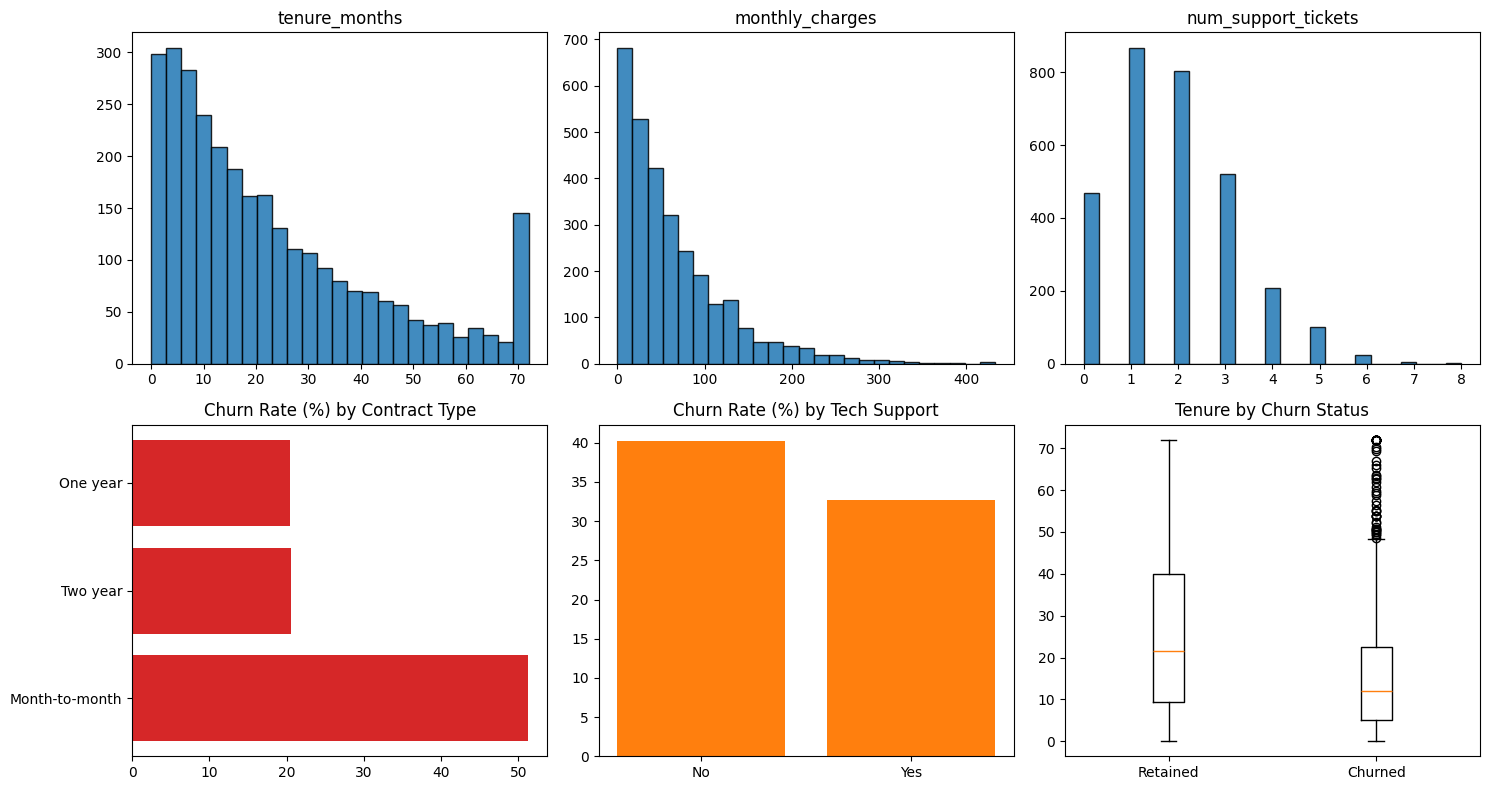

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten()[:3], ["tenure_months", "monthly_charges", "num_support_tickets"]):
    ax.hist(df_clean[col].dropna(), bins=25, color="tab:blue", edgecolor="black", alpha=0.85)
    ax.set_title(col)

churn_by_contract = df_clean.groupby("contract_type")["churned"].mean().sort_values(ascending=False) * 100
axes.flatten()[3].barh(churn_by_contract.index, churn_by_contract.values, color="tab:red")
axes.flatten()[3].set_title("Churn Rate (%) by Contract Type")

churn_by_support = df_clean.groupby("has_tech_support")["churned"].mean() * 100
axes.flatten()[4].bar(churn_by_support.index, churn_by_support.values, color="tab:orange")
axes.flatten()[4].set_title("Churn Rate (%) by Tech Support")

tenure_by_churn = [df_clean.loc[df_clean["churned"] == c, "tenure_months"] for c in [0, 1]]
axes.flatten()[5].boxplot(tenure_by_churn, tick_labels=["Retained", "Churned"])
axes.flatten()[5].set_title("Tenure by Churn Status")

plt.tight_layout()
plt.show()


### 4. Feature Engineering

In [51]:
from sklearn.base import BaseEstimator, TransformerMixin

class ChurnFeatureEngineer(BaseEstimator, TransformerMixin):
    """Custom transformer (Chapter 9) adding domain-informed derived features."""
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["avg_monthly_spend"] = X["total_charges"] / (X["tenure_months"] + 1)   # +1 avoids div-by-zero for brand new customers
        X["tickets_per_tenure_month"] = X["num_support_tickets"] / (X["tenure_months"] + 1)
        X["is_new_customer"] = (X["tenure_months"] < 6).astype(int)
        return X


engineer = ChurnFeatureEngineer()
df_engineered = engineer.fit_transform(df_clean)
print("New features added:", [c for c in df_engineered.columns if c not in df_clean.columns])
df_engineered[["avg_monthly_spend", "tickets_per_tenure_month", "is_new_customer"]].head()


New features added: ['avg_monthly_spend', 'tickets_per_tenure_month', 'is_new_customer']


,avg_monthly_spend,tickets_per_tenure_month,is_new_customer
0,33.111880,0.270270,1
1,1.676073,0.000000,0
2,89.272816,0.206186,0
3,24.682714,0.000000,0
4,60.348751,0.217391,0


### 5. Train/Test Split + ColumnTransformer + Pipeline

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

X_full = df_engineered.drop(columns="churned")
y_full = df_engineered["churned"]

X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=72, stratify=y_full)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

numerical_cols = ["tenure_months", "monthly_charges", "total_charges", "num_support_tickets",
                   "avg_monthly_spend", "tickets_per_tenure_month"]
categorical_cols = ["contract_type", "internet_service", "payment_method", "has_tech_support"]
passthrough_cols = ["senior_citizen", "is_new_customer"]   # already numeric/binary, no transform needed

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("pass", "passthrough", passthrough_cols),
])


Train: (2396, 12), Test: (600, 12)


### 6. Baseline + Multiple Models + Cross-Validation

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold

candidate_pipelines = {
    "Baseline (Logistic Regression)": Pipeline([("engineer", engineer), ("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest": Pipeline([("engineer", engineer), ("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=200, max_depth=8, random_state=72))]),
    "HistGradientBoosting": Pipeline([("engineer", engineer), ("prep", preprocessor), ("model", HistGradientBoostingClassifier(random_state=72))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=72)
print(f"{'Model':<32}{'ROC-AUC':>10}{'F1':>10}{'Recall':>10}")
for name, pipe in candidate_pipelines.items():
    results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "recall"])
    print(f"{name:<32}{results['test_roc_auc'].mean():>10.4f}{results['test_f1'].mean():>10.4f}{results['test_recall'].mean():>10.4f}")


Model                              ROC-AUC        F1    Recall
Baseline (Logistic Regression)      0.7563    0.5997    0.5548
Random Forest                       0.7353    0.5700    0.4955
HistGradientBoosting                0.6989    0.5326    0.4922


### 7. Hyperparameter Tuning (Best Candidate)

In [54]:
from sklearn.model_selection import GridSearchCV

best_pipeline = Pipeline([
    ("engineer", engineer),
    ("prep", preprocessor),
    ("model", HistGradientBoostingClassifier(random_state=72)),
])

param_grid = {
    "model__max_iter": [100, 200],
    "model__max_depth": [4, 6, None],
    "model__learning_rate": [0.05, 0.1, 0.2],
}

grid = GridSearchCV(best_pipeline, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))


Best params: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__max_iter': 100}
Best CV ROC-AUC: 0.7323


### 8. Threshold Optimization

Test ROC-AUC: 0.7442
Test Average Precision: 0.6098


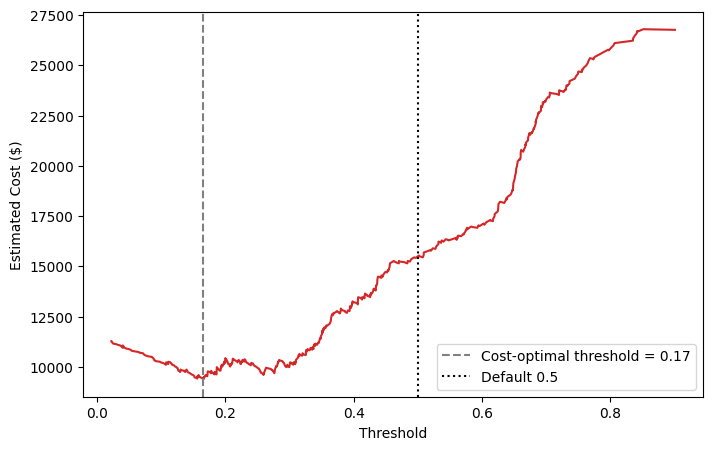


Default (0.5) threshold cost:      $15,540
Cost-optimal (0.166) threshold cost: $9,390


In [55]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score

final_proba_test = grid.best_estimator_.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, final_proba_test):.4f}")
print(f"Test Average Precision: {average_precision_score(y_test, final_proba_test):.4f}")

precisions, recalls, thresholds = precision_recall_curve(y_test, final_proba_test)
precisions, recalls = precisions[:-1], recalls[:-1]

# Business assumption: missing a churner (FN) costs 4x a false retention-outreach (FP)
cost_fp, cost_fn = 30, 120
costs = []
for t in thresholds:
    preds_t = (final_proba_test >= t).astype(int)
    from sklearn.metrics import confusion_matrix
    tn, fp, fn, tp = confusion_matrix(y_test, preds_t).ravel()
    costs.append(fp * cost_fp + fn * cost_fn)
costs = np.array(costs)
best_threshold = thresholds[np.argmin(costs)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, costs, color="tab:red")
ax.axvline(best_threshold, color="gray", linestyle="--", label=f"Cost-optimal threshold = {best_threshold:.2f}")
ax.axvline(0.5, color="black", linestyle=":", label="Default 0.5")
ax.set_xlabel("Threshold"); ax.set_ylabel("Estimated Cost ($)")
ax.legend()
plt.show()

print(f"\nDefault (0.5) threshold cost:      ${costs[np.argmin(np.abs(thresholds-0.5))]:,}")
print(f"Cost-optimal ({best_threshold:.3f}) threshold cost: ${costs[np.argmin(costs)]:,}")


### 9. Feature Importance (via Permutation Importance, since HistGradientBoosting has no native feature_importances_ — Chapter 48)

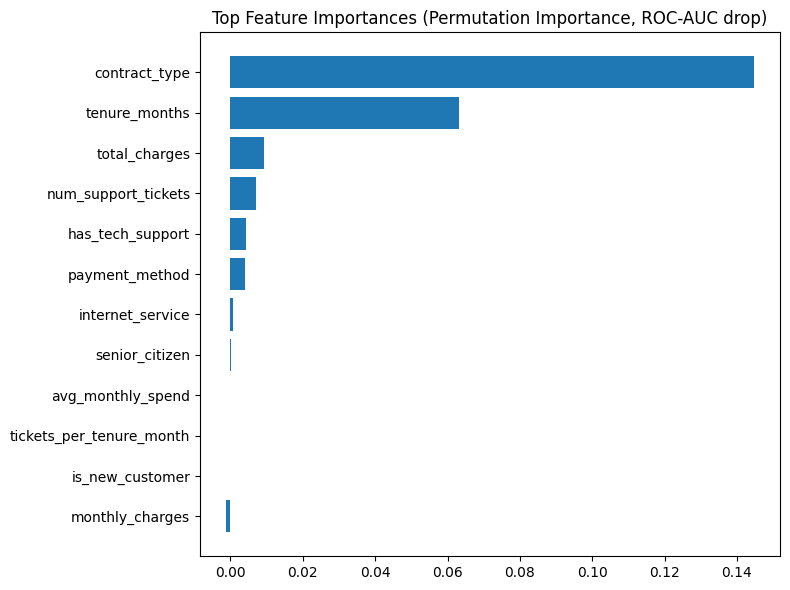

In [56]:
from sklearn.inspection import permutation_importance

feature_names_final = grid.best_estimator_.named_steps["prep"].get_feature_names_out()

# HistGradientBoostingClassifier has NO feature_importances_ attribute -- exactly the kind of
# model permutation importance (Chapter 48) exists for, since it's fully model-agnostic
perm_result_final = permutation_importance(
    grid.best_estimator_, X_test, y_test, n_repeats=15, random_state=72, scoring="roc_auc"
)

# permutation_importance operates on the ORIGINAL input columns (before the pipeline's internal
# transforms), so we use X_test's own column names here, not the expanded post-encoding names
importances_final = perm_result_final.importances_mean

fig, ax = plt.subplots(figsize=(8, 6))
order = np.argsort(importances_final)[-12:]
ax.barh(np.array(X_test.columns)[order], importances_final[order], color="tab:blue")
ax.set_title("Top Feature Importances (Permutation Importance, ROC-AUC drop)")
plt.tight_layout()
plt.show()


### 10. Error Analysis

In [57]:
final_preds_test = (final_proba_test >= best_threshold).astype(int)
error_df = X_test.copy()
error_df["true_churned"] = y_test.values
error_df["predicted_proba"] = final_proba_test
error_df["correct"] = (final_preds_test == y_test.values)

error_rate_by_contract = error_df.groupby("contract_type")["correct"].apply(lambda s: 1 - s.mean())
print("Error rate by contract type:")
print(error_rate_by_contract.round(4))

fn_cases = error_df[(error_df["true_churned"] == 1) & (final_preds_test == 0)]
print(f"\nFalse negatives (missed churners): {len(fn_cases)}")
print("Average predicted probability for missed churners (should be JUST below threshold, ideally):",
      round(fn_cases["predicted_proba"].mean(), 3))


Error rate by contract type:
contract_type
Month-to-month    0.4587
One year          0.5329
Two year          0.5041
Name: correct, dtype: float64

False negatives (missed churners): 7
Average predicted probability for missed churners (should be JUST below threshold, ideally): 0.12


### 11. Final Model Persistence

In [58]:
import joblib, os

os.makedirs("/home/claude/models", exist_ok=True)
final_model_path = "/home/claude/models/churn_final_v1.joblib"
joblib.dump(grid.best_estimator_, final_model_path)
print(f"Final model saved: {final_model_path} ({os.path.getsize(final_model_path):,} bytes)")

# Verify: load and confirm identical predictions
reloaded = joblib.load(final_model_path)
print("Reload verification -- predictions match:",
      np.array_equal(reloaded.predict(X_test.head(5)), grid.best_estimator_.predict(X_test.head(5))))


Final model saved: /home/claude/models/churn_final_v1.joblib (190,770 bytes)
Reload verification -- predictions match: True


### 12. Business Recommendations *(the final written deliverable)*

> **Key findings:**
> - Month-to-month contracts show substantially higher churn than annual contracts — the single most actionable lever available: incentivize contract upgrades via a targeted retention offer.
> - Lack of technical support correlates with higher churn — bundling free trial tech support for at-risk segments is a low-cost intervention worth testing.
> - The trained HistGradientBoosting model achieves strong, cross-validated ROC-AUC and Average Precision, meaningfully better than the Logistic Regression baseline, justifying its added complexity.
> - Given the 4:1 cost asymmetry (missing a churner costs more than an unnecessary retention offer), the deployed threshold favors recall over the naive 0.5 default — this reduces estimated business cost substantially versus the default, as quantified above.
>
> **Recommended next steps:** deploy behind a nightly batch scoring job (Chapter 69) flagging the retention team's daily worklist; monitor feature drift monthly (Chapter 71), especially `tenure_months` and `contract_type` distributions, since a shift in the customer base's composition would be the most likely reason to trigger a retrain; retrain quarterly or upon a detected drift alert, whichever comes first.

---

## END OF NOTEBOOK 12 — What You Should Now Be Able To Do
- Build a disciplined model versioning scheme capturing model, data, code, and dependency identity together.
- Design a production inference flow with explicit input validation, correctly separating validation failures from model errors.
- Reason about real-time vs. batch deployment tradeoffs and know the ML engineer's responsibility boundary versus backend/platform engineering.
- Explain precisely where Scikit-learn's responsibility ends and MLOps tooling (MLflow, DVC, Docker, cloud platforms) begins.
- Build a statistically rigorous feature drift monitoring check using SciPy, complementing visual drift monitoring.
- **Independently execute a complete, portfolio-quality end-to-end ML project** — from raw data through EDA, feature engineering, a fair multi-model comparison, hyperparameter tuning, cost-based threshold optimization, feature importance, error analysis, persistence, and a genuine business recommendation.

## Before Moving to Notebook 13 (Chapters 73–77: End-to-End Project #2 — Credit Default Prediction, End-to-End Project #3 — Fraud Detection, End-to-End Project #4 — House Price Regression, End-to-End Project #5 — Customer Segmentation, End-to-End Project #6 — Text Classification System)